# NN-Interp: learning multiplication

We train a small **2 → 4 → 4 → 1** network on independent uniform inputs in $[-2, 2]^2$, with target $xy$. The hidden layers use `tanh`, and the output is linear. With only four neurons per hidden layer, expect an approximation rather than exact multiplication.

Then we print five examples from each of four cases, fit a separate **4 → 1 linear probe** to each frozen hidden layer, and compare the learned surface to $z = xy$.

Run the cells from top to bottom. Only PyTorch and Matplotlib are required.

In [1]:
# Run this once if the packages are missing, then restart the kernel:
# %pip install torch matplotlib

In [2]:
import torch
from torch import nn
import matplotlib.pyplot as plt

# A small CPU model; one thread avoids overhead for these tiny matrices.
torch.set_num_threads(1)
torch.manual_seed(42)
plt.rcParams["figure.figsize"] = (8, 4)


def sample_inputs(n):
    return 4 * torch.rand(n, 2) - 2


def product(inputs):
    return inputs[:, :1] * inputs[:, 1:2]


train_x = sample_inputs(4096)
test_x = sample_inputs(4096)  # Held out from model and probe training.
train_y = product(train_x)
test_y = product(test_x)

Matplotlib is building the font cache; this may take a moment.


## Train the multiplication network

`activations()` returns the values **after** each hidden layer's `tanh`. The output layer has no activation so it can predict both positive and negative products.

Held-out MSE: 0.000117
Held-out MAE: 0.007713


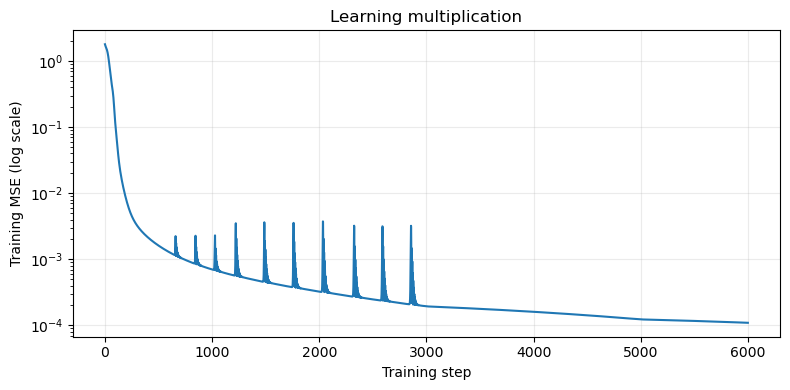

In [3]:
class MultiplicationNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.hidden1 = nn.Linear(2, 4)
        self.hidden2 = nn.Linear(4, 4)
        self.output = nn.Linear(4, 1)

    def activations(self, inputs):
        h1 = torch.tanh(self.hidden1(inputs))
        h2 = torch.tanh(self.hidden2(h1))
        return h1, h2

    def forward(self, inputs):
        _, h2 = self.activations(inputs)
        return self.output(h2)


model = MultiplicationNet()
optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
scheduler = torch.optim.lr_scheduler.MultiStepLR(
    optimizer, milestones=[3000, 5000], gamma=0.3
)
loss_fn = nn.MSELoss()
losses = []

model.train()
for step in range(6000):
    prediction = model(train_x)
    loss = loss_fn(prediction, train_y)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    scheduler.step()
    losses.append(loss.item())

model.eval()
with torch.no_grad():
    test_prediction = model(test_x)
    print(f"Held-out MSE: {loss_fn(test_prediction, test_y).item():.6f}")
    print(f"Held-out MAE: {(test_prediction - test_y).abs().mean().item():.6f}")

plt.semilogy(losses)
plt.xlabel("Training step")
plt.ylabel("Training MSE (log scale)")
plt.title("Learning multiplication")
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## Inspect the four cases

1. Both inputs are in $[-1, 1]$.
2. Both inputs are in $[-2, -1] \cup [1, 2]$ (sample signs independently).
3. $x = 0$, with $y$ uniform on $[-2, 2]$.
4. $y = 0$, with $x$ uniform on $[-2, 2]$.

These cases are diagnostic slices, not a partition of the whole square: mixed inner/outer inputs are still included in training and the overall test set. The origin belongs to both zero-input slices.

Activation signs, saturation near ±1, and changes under input sign flips may suggest patterns. A neuron's activation alone does not establish what computation it performs.

In [4]:
def make_cases(n, seed):
    generator = torch.Generator().manual_seed(seed)
    inner = 2 * torch.rand(n, 2, generator=generator) - 1
    signs = 2 * torch.randint(0, 2, (n, 2), generator=generator) - 1
    outer = signs * (1 + torch.rand(n, 2, generator=generator))
    x_zero = 4 * torch.rand(n, 2, generator=generator) - 2
    x_zero[:, 0] = 0
    y_zero = 4 * torch.rand(n, 2, generator=generator) - 2
    y_zero[:, 1] = 0
    return {"Both inner": inner, "Both outer": outer,
            "x = 0": x_zero, "y = 0": y_zero}


def vector_string(values):
    return "[" + ", ".join(f"{v:+.3f}" for v in values.tolist()) + "]"


examples = make_cases(5, seed=123)
with torch.no_grad():
    for name, inputs in examples.items():
        h1, h2 = model.activations(inputs)
        predictions = model(inputs)
        print(f"\n{name}")
        for i in range(len(inputs)):
            print(f"x={inputs[i, 0]:+.3f}  y={inputs[i, 1]:+.3f}  "
                  f"xy={product(inputs)[i, 0]:+.3f}  pred={predictions[i, 0]:+.3f}")
            print(f"  h1={vector_string(h1[i])}  h2={vector_string(h2[i])}")


Both inner
x=-0.408  y=+0.033  xy=-0.014  pred=-0.009
  h1=[-0.884, -0.812, +0.870, -0.777]  h2=[+0.252, -0.889, -0.183, -0.951]
x=-0.497  y=+0.377  xy=-0.187  pred=-0.177
  h1=[-0.862, -0.838, +0.900, -0.710]  h2=[+0.298, -0.898, -0.152, -0.943]
x=-0.852  y=+0.733  xy=-0.625  pred=-0.612
  h1=[-0.860, -0.835, +0.935, -0.563]  h2=[+0.401, -0.915, -0.061, -0.913]
x=-0.727  y=-0.795  xy=+0.578  pred=+0.563
  h1=[-0.947, -0.630, +0.825, -0.837]  h2=[+0.115, -0.838, -0.294, -0.965]
x=-0.632  y=+0.453  xy=-0.286  pred=-0.275
  h1=[-0.867, -0.831, +0.912, -0.671]  h2=[+0.323, -0.902, -0.133, -0.937]

Both outer
x=+1.854  y=+1.593  xy=+2.953  pred=+2.953
  h1=[-0.078, -0.986, +0.800, -0.862]  h2=[-0.375, -0.398, -0.650, -0.990]
x=-1.637  y=+1.983  xy=-3.245  pred=-3.235
  h1=[-0.805, -0.869, +0.982, +0.074]  h2=[+0.770, -0.966, +0.442, -0.328]
x=-1.274  y=+1.658  xy=-2.114  pred=-2.117
  h1=[-0.803, -0.875, +0.972, -0.165]  h2=[+0.657, -0.951, +0.255, -0.671]
x=-1.278  y=+1.857  xy=-2.373  p

## Fit linear interpreting models

Each probe is an independent `nn.Linear(4, 1)` trained to reproduce the **network's predictions**, rather than the true product. We detach the hidden activations so probe training cannot change the original network. We use new training inputs and keep the earlier test inputs held out.

Since these are small linear regression problems, PyTorch's L-BFGS optimizer converges quickly with full batches. We report both probe-to-network MSE (fidelity) and probe-to-product MSE (task accuracy).

The second probe has exactly the same inputs and form as the original output layer, so high fidelity is expected. The first probe tests how much of the network's prediction is already linearly readable before the second nonlinear layer. Neither probe proves a causal explanation of the network.

In [5]:
torch.manual_seed(7)
probe_train_x = sample_inputs(4096)
with torch.no_grad():
    probe_features = model.activations(probe_train_x)
    probe_targets = model(probe_train_x)


def fit_probe(features, targets):
    probe = nn.Linear(4, 1)
    optimizer = torch.optim.LBFGS(
        probe.parameters(), lr=1.0, max_iter=200,
        tolerance_grad=1e-10, tolerance_change=1e-12,
        line_search_fn="strong_wolfe",
    )

    def closure():
        optimizer.zero_grad()
        loss = loss_fn(probe(features), targets)
        loss.backward()
        return loss

    optimizer.step(closure)
    probe.eval()
    return probe


probe1 = fit_probe(probe_features[0], probe_targets)
probe2 = fit_probe(probe_features[1], probe_targets)

for name, probe in [("Hidden layer 1", probe1), ("Hidden layer 2", probe2)]:
    print(f"{name}: weights={vector_string(probe.weight.detach()[0])}, "
          f"bias={probe.bias.item():+.3f}")

Hidden layer 1: weights=[+4.487, +4.462, +4.606, -4.434], bias=+0.142
Hidden layer 2: weights=[-1.599, +1.850, -2.130, -1.481], bias=+0.240


In [6]:
evaluation_cases = {"Whole square": test_x, **make_cases(1024, seed=456)}
print(f"{'Case':<16} {'NN vs xy':>12} {'P1 vs NN':>12} {'P1 vs xy':>12} "
      f"{'P2 vs NN':>12} {'P2 vs xy':>12}")

with torch.no_grad():
    for name, inputs in evaluation_cases.items():
        target = product(inputs)
        prediction = model(inputs)
        h1, h2 = model.activations(inputs)
        p1, p2 = probe1(h1), probe2(h2)
        errors = [loss_fn(a, b).item() for a, b in [
            (prediction, target), (p1, prediction), (p1, target),
            (p2, prediction), (p2, target),
        ]]
        print(f"{name:<16}" + "".join(f"{error:12.6f}" for error in errors))

    print("\nFive-example predictions (same inputs as the activation printout):")
    for name, inputs in examples.items():
        h1, h2 = model.activations(inputs)
        print(f"\n{name}")
        print("     x       y      xy      NN      P1      P2")
        rows = torch.cat([inputs, product(inputs), model(inputs),
                          probe1(h1), probe2(h2)], dim=1)
        for row in rows:
            print(" ".join(f"{value:+7.3f}" for value in row.tolist()))

Case                 NN vs xy     P1 vs NN     P1 vs xy     P2 vs NN     P2 vs xy
Whole square        0.000117    0.001335    0.001422    0.000000    0.000117
Both inner          0.000078    0.000454    0.000219    0.000000    0.000078
Both outer          0.000276    0.002745    0.003487    0.000000    0.000276
x = 0               0.000014    0.000352    0.000422    0.000000    0.000014
y = 0               0.000013    0.000188    0.000248    0.000000    0.000013

Five-example predictions (same inputs as the activation printout):

Both inner
     x       y      xy      NN      P1      P2
 -0.408  +0.033  -0.014  -0.009  +0.000  -0.009
 -0.497  +0.377  -0.187  -0.177  -0.177  -0.177
 -0.852  +0.733  -0.625  -0.612  -0.639  -0.612
 -0.727  -0.795  +0.578  +0.563  +0.594  +0.563
 -0.632  +0.453  -0.286  -0.275  -0.281  -0.275

Both outer
     x       y      xy      NN      P1      P2
 +1.854  +1.593  +2.953  +2.953  +2.897  +2.953
 -1.637  +1.983  -3.245  -3.235  -3.155  -3.235
 -1.274  +1

## Plot the learned surface

The graph $(x, y, f(x, y))$ is a two-dimensional surface in 3D. All panels use the same input grid and output limits. The error map below helps reveal discrepancies that can be hard to see in the surfaces.

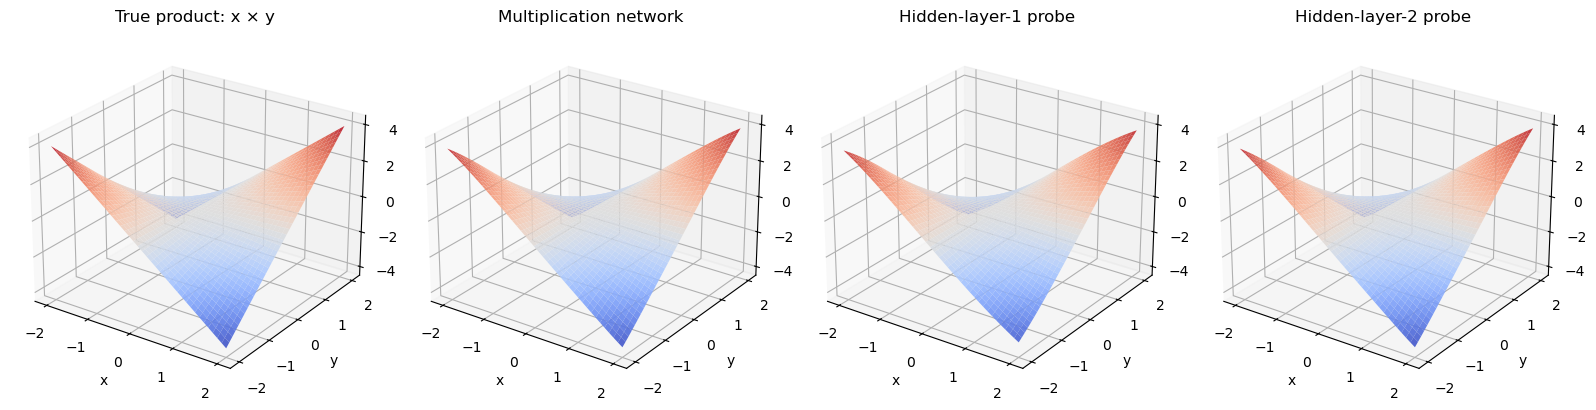

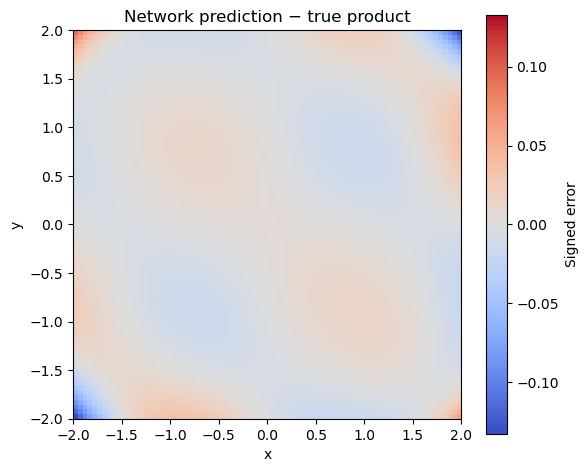

In [7]:
axis = torch.linspace(-2, 2, 81)
xx, yy = torch.meshgrid(axis, axis, indexing="xy")
grid = torch.stack([xx.flatten(), yy.flatten()], dim=1)

with torch.no_grad():
    h1, h2 = model.activations(grid)
    surfaces = [product(grid), model(grid), probe1(h1), probe2(h2)]
    surfaces = [surface.reshape(xx.shape).numpy() for surface in surfaces]

fig = plt.figure(figsize=(16, 4))
for i, (title, surface) in enumerate(zip(
    ["True product: x × y", "Multiplication network", "Hidden-layer-1 probe", "Hidden-layer-2 probe"],
    surfaces,
)):
    ax = fig.add_subplot(1, 4, i + 1, projection="3d")
    ax.plot_surface(xx.numpy(), yy.numpy(), surface, cmap="coolwarm",
                    vmin=-4, vmax=4, linewidth=0, alpha=0.9)
    ax.set(xlabel="x", ylabel="y", zlabel="Output", title=title, zlim=(-4.5, 4.5))
    ax.view_init(elev=25, azim=-55)
fig.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(6, 5))
error = surfaces[1] - surfaces[0]
limit = max(float(abs(error).max()), 1e-8)
plot = ax.imshow(error, origin="lower", extent=(-2, 2, -2, 2),
                 cmap="coolwarm", vmin=-limit, vmax=limit, aspect="equal")
ax.set(xlabel="x", ylabel="y", title="Network prediction − true product")
fig.colorbar(plot, ax=ax, label="Signed error")
plt.tight_layout()
plt.show()

Try changing the seed, number of training steps, or hidden activation and rerunning all cells. Compare overall test error, behavior along the zero-input axes, and first-layer probe fidelity. Probe weights depend on the learned representation and can change across runs, even when the output surface is similar.